# Label cleaning checks

**Question:** The transition fix (`fix_transitions`) treats a value as "arrived" at a label when it stays within `tol` of a whole number for 3 rows. During a slide from 1 to 0, a first value like 0.90 lies within 0.1 of 1, so with `tol = 0.1` it keeps the label 1 even though the slide has started.

- Does this create many wrong rows?
- Does a stricter tolerance lose bumps?
- Which `tol` should we use?

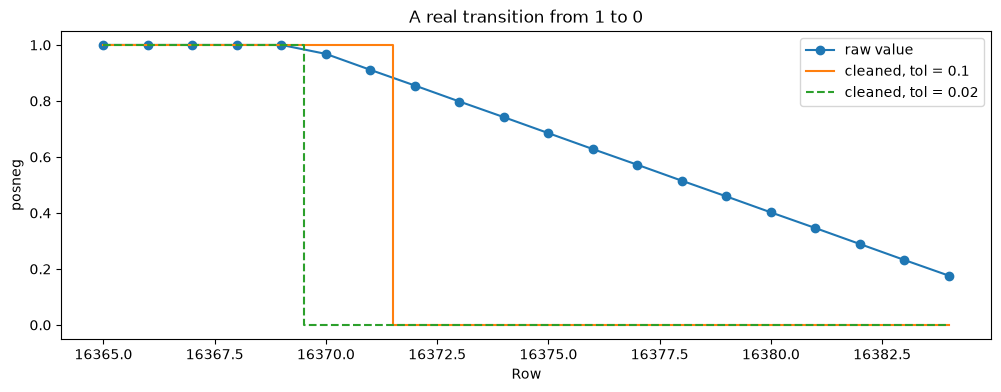

[1.0, 1.0, 1.0, 1.0, 1.0, 0.968, 0.911, 0.855, 0.798, 0.742, 0.685, 0.628, 0.572, 0.515, 0.459, 0.402, 0.346, 0.289, 0.232, 0.176]


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from data_utils import fix_transitions

files = sorted(Path("../dataset").glob("*.txt"))

raw = pd.read_csv(files[0], sep="\t", dtype=str)
values = pd.to_numeric(raw["posneg"].str.replace(",", ".")).ffill()

# find the first place where a slide from 1 down to 0 begins
start = None
for i in range(1, len(values)):
    if values[i - 1] >= 0.99 and 0 < values[i] < 0.99:
        start = i
        break

part = values[start - 5 : start + 15]

plt.figure(figsize=(12, 4))
plt.plot(part.index, part, "o-", label="raw value")
plt.step(part.index, fix_transitions(values, tol=0.1)[part.index], where="mid", label="cleaned, tol = 0.1")
plt.step(part.index, fix_transitions(values, tol=0.02)[part.index], where="mid", linestyle="--", label="cleaned, tol = 0.02")
plt.xlabel("Row")
plt.ylabel("posneg")
plt.title("A real transition from 1 to 0")
plt.legend()
plt.savefig("figures/transition_tolerance.png", dpi=150)
plt.show()

print(part.round(3).tolist())

* A real 1 > 0 slide . With tol = 0.1, the first two slide values (0.968, 0.911) keep the label 1. With tol = 0.02, the boundary falls exactly where the slide starts.

In [2]:
import pandas as pd
from pathlib import Path
from data_utils import fix_transitions

def count_bumps(flag):
    return (flag & ~flag.shift(fill_value=False)).sum()

files = sorted(Path("../dataset").glob("*.txt"))

raw_total = 0
for f in files:
    raw = pd.read_csv(f, sep="\t", dtype=str)
    posneg = pd.to_numeric(raw["posneg"].str.replace(",", ".")).ffill()
    raw_total = raw_total + count_bumps(posneg > 0.5)
print("Bumps in raw data:", raw_total)

for tol in [0.02, 0.05, 0.1, 0.14]:
    total = 0
    for f in files:
        raw = pd.read_csv(f, sep="\t", dtype=str)
        posneg = pd.to_numeric(raw["posneg"].str.replace(",", ".")).ffill()
        cleaned = fix_transitions(posneg, tol=tol)
        total = total + count_bumps(cleaned > 0)
    print("tol =", tol, "→ bumps after cleaning:", total)

Bumps in raw data: 54
tol = 0.02 → bumps after cleaning: 54
tol = 0.05 → bumps after cleaning: 54
tol = 0.1 → bumps after cleaning: 54
tol = 0.14 → bumps after cleaning: 54


In [3]:
import pandas as pd
from pathlib import Path
from data_utils import fix_transitions

files = sorted(Path("../dataset").glob("*.txt"))

total_rows = 0
different_rows = 0

for f in files:
    raw = pd.read_csv(f, sep="\t", dtype=str)
    total_rows = total_rows + len(raw)
    for col in ["posneg", "vaikeus", "muu"]:
        values = pd.to_numeric(raw[col].str.replace(",", ".")).ffill()
        with_01 = fix_transitions(values, tol=0.1)
        with_002 = fix_transitions(values, tol=0.02)
        different_rows = different_rows + (with_01 != with_002).sum()

print("Rows in all files:", total_rows)
print("Label values that differ between tol 0.1 and 0.02:", different_rows)

Rows in all files: 444083
Label values that differ between tol 0.1 and 0.02: 1096


## Conclusion

* 'The issue is real'. In a real 1 > 0 transition, 'tol = 0.1' kept the label 1 for the first two slide values (0.968, 0.911), although the slide had already started. With 'tol = 0.02', the boundry falls exactly where the slide begins.

* 'But small'. across all files, 1096 of ~1.33 million label values (444,083 rows × 3 label columns) differ between 'tol = 0.1' and 'tol = 0.02', which is '0.08%'.

* 'No bumps lost with a stricter tolerance'. 54 bumps in the raw data, and 54 after cleaning for every tolerance from 0.02 to 0.14.

* 'No false labels:' a label sometimes passes 'through' another code on its way, e.g. 'muu' sliding from 0 (nothing) to 3 (hole) passes 1 (frost heave). With slow slides and 'tol = 0.1', the values near 1 could be mistaken for "arrived at 1", creating a few rows of false frost heave. With 'tol = 0.02', the band is too narrow for this to happen.

* 'Decision: switch to 0.02'. It places boundries where transitions begin, rules out false intermediate labels, and loses no bumps. The effect on later results is expected to be very small (0.08 of label values).

In [2]:
import pandas as pd
from pathlib import Path
from data_utils import load_clean

files = sorted(Path("../dataset").glob("*.txt"))

for f in files:
    raw = pd.read_csv(f, sep="\t", dtype=str)
    clean = load_clean(f, trim=True)
    kept_first, kept_last = clean.index.min(), clean.index.max()

    # Point 3: empty labels
    empty = raw["muu"].isna()
    if empty.sum() > 0:
        first_empty, last_empty = empty[empty].index.min(), empty[empty].index.max()
    else:
        first_empty, last_empty = None, None

    # Point 2: jumps in time and distance
    timer = pd.to_numeric(raw["Timer(ms)"].str.replace(",", "."))
    loc = pd.to_numeric(raw["Loc(m)"].str.replace(",", "."))
    time_jumps = timer.diff()[timer.diff() > 5].index.tolist()
    if len(time_jumps) > 0:
        print(f"  number of time jumps: {len(time_jumps)} | last one at row {time_jumps[-1]}")
    loc_jumps = loc.diff()[loc.diff() > 1].index.tolist()

    print(f.stem.split("_RDMC")[0])
    print(f"  rows: {len(raw)} | kept after trimming: rows {kept_first}–{kept_last}")
    print(f"  empty labels: {empty.sum()} | at rows {first_empty}–{last_empty}")
    print(f"  time jumps (> 5 ms) at rows: {time_jumps[:10]}")
    print(f"  distance jumps (> 1 m) at rows: {loc_jumps[:10]}")

..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
  number of time jumps: 1538 | last one at row 5077
Iisingintie_Acc1_m800
  rows: 69125 | kept after trimming: rows 8242–65114
  empty labels: 0 | at rows None–None
  time jumps (> 5 ms) at rows: [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
  distance jumps (> 1 m) at rows: []
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
  number of time jumps: 1260 | last one at row 2995
Iisingintie_Acc1_m801
  rows: 83597 | kept after trimming: rows 7032–82496
  empty labels: 0 | at rows None–None
  time jumps (> 5 ms) at rows: [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
  distance jumps (> 1 m) at rows: []
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
  number of time jumps: 1779 | last one at row 122620
Iisingintie_Acc1_m802
  rows: 122623 | kept after trimming: rows 4929–119612
  empty labels: 0 | at rows None–None
  time jumps (> 5 ms) at rows: [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
  dist

In [3]:
import importlib
from pathlib import Path
import data_utils
importlib.reload(data_utils)
from data_utils import load_clean

files = sorted(Path("../dataset").glob("*.txt"))

for f in files:
    before = load_clean(f, trim=True, continuous=False)
    after = load_clean(f, trim=True, continuous=True)
    print(f.stem.split("_RDMC")[0], "| removed rows:", len(before) - len(after))

..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
Iisingintie_Acc1_m800 | removed rows: 0
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
Iisingintie_Acc1_m801 | removed rows: 0
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
Iisingintie_Acc1_m802 | removed rows: 0
..\dataset\Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.txt: 108473 rows
..\dataset\Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.txt: 108473 rows
Kaittiaisentie_Acc1 | removed rows: 0
..\dataset\sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.txt: 6426 rows
..\dataset\sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.txt: 6426 rows
sinetänsalmentie_Acc1_m792 | removed rows: 0
..\dataset\sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.txt: 766

### Workshop checks: missing labels and time discontinuities

- **Missing labels:** only in Kaittiaisentie (993 rows, rows 113,950–114,942), after the part kept by trimming (up to row 112,998). No missing labels in the data we use.
- **Time discontinuities (gaps > 5 ms):**
  - Iisingintie m800, m801, m802: many gaps at the very start (sensor warm-up, every other row) and, for m802, at the very end. All lie outside the part kept by trimming.
  - Kaittiaisentie and m793: one gap each, outside the kept part.
  - **m795: one time and distance gap at row 55, inside the kept part** (this drive needed no trimming).
- **Fix:** after trimming, `load_clean` now keeps only the longest stretch without time gaps (`keep_longest_continuous`). This removes the first 55 rows of m795 and nothing from any other drive.